In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bf = pd.read_csv("../data/processed/battery_fire_recalls.csv",
                 index_col="CAMPNO", parse_dates=["RCDATE"])

main = bf[bf["battery_type"] != "Battery (text only)"]   # component-based set
print("All battery-fire recalls:", len(bf))
print("Main set (HV + 12V):", len(main))
print(main["battery_type"].value_counts())

All battery-fire recalls: 347
Main set (HV + 12V): 243
battery_type
12V/24V/48V battery    132
HV traction battery    111
Name: count, dtype: int64


battery_type  12V/24V/48V battery  HV traction battery
year                                                  
2010                           10                    0
2011                           10                    1
2012                            4                    2
2013                            5                    0
2014                            6                    0
2015                           11                    0
2016                            6                    0
2017                            9                    0
2018                            8                    0
2019                           10                    1
2020                           11                    5
2021                            5                    3
2022                            8                    5
2023                           11                   22
2024                            8                   25
2025                            8                   29


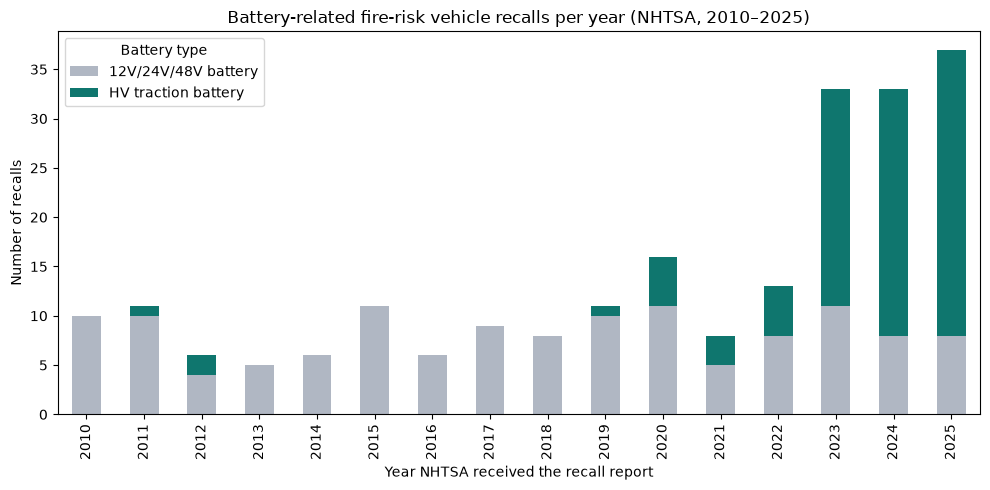

2026 (partial, to 21 Oct): 20 recalls


In [2]:
# Exclude 2026: data ends on 21 Oct 2026, so it is a partial year
counts = (main[main["year"] <= 2025]
          .groupby(["year", "battery_type"]).size()
          .unstack(fill_value=0))
print(counts)

colors = {"HV traction battery": "#0F766E", "12V/24V/48V battery": "#B0B7C3"}
ax = counts.plot(kind="bar", stacked=True, figsize=(10, 5),
                 color=[colors[c] for c in counts.columns])
ax.set_title("Battery-related fire-risk vehicle recalls per year (NHTSA, 2010–2025)")
ax.set_xlabel("Year NHTSA received the recall report")
ax.set_ylabel("Number of recalls")
ax.legend(title="Battery type")
plt.tight_layout()
plt.savefig("../figures/01_recalls_per_year.png", dpi=150)
plt.show()

print("2026 (partial, to 21 Oct):", (main["year"] == 2026).sum(), "recalls")

In [3]:
# Is the HV jump real, or just NHTSA starting to use the "TRACTION BATTERY" code?
# Compare the component flag with an independent text-based flag, year by year.
rec = pd.read_csv("../data/processed/vehicle_recalls.csv",
                  index_col="CAMPNO", dtype={"RCDATE": str})
rec["year"] = rec["RCDATE"].str[:4].astype(int)
rec = rec[rec["year"] <= 2025]

text = rec["DESC_DEFECT"] + " " + rec["CONEQUENCE_DEFECT"]
rec["hv_text"] = text.str.contains(r"HIGH[- ]VOLTAGE|TRACTION BATTERY|LITHIUM",
                                   case=False, regex=True)

check = rec.groupby("year")[["hv_comp", "hv_text"]].sum()
check["all_vehicle_recalls"] = rec.groupby("year").size()
check

,hv_comp,hv_text,all_vehicle_recalls
year,,,
2010,0,0,647
2011,1,2,597
2012,2,2,583
2013,0,0,627
2014,1,1,770
2015,1,1,863
2016,3,6,919
2017,0,1,810
2018,1,3,912


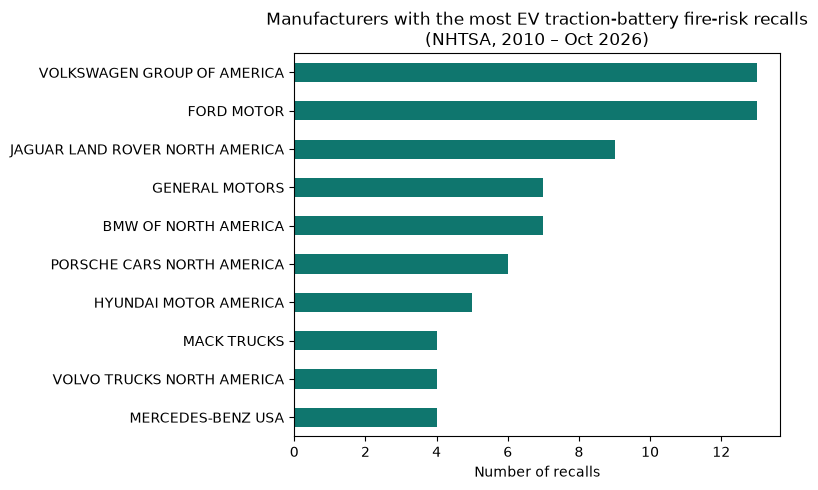

mfr
VOLKSWAGEN GROUP OF AMERICA        13
FORD MOTOR                         13
JAGUAR LAND ROVER NORTH AMERICA     9
BMW OF NORTH AMERICA                7
GENERAL MOTORS                      7
PORSCHE CARS NORTH AMERICA          6
HYUNDAI MOTOR AMERICA               5
MERCEDES-BENZ USA                   4
VOLVO TRUCKS NORTH AMERICA          4
MACK TRUCKS                         4
Name: count, dtype: int64


In [4]:
hv = main[main["battery_type"] == "HV traction battery"]
top = hv["mfr"].value_counts().head(10).sort_values()   # ascending so the largest is on top

ax = top.plot(kind="barh", color="#0F766E", figsize=(8, 5))
ax.set_title("Manufacturers with the most EV traction-battery fire-risk recalls\n(NHTSA, 2010 – Oct 2026)")
ax.set_xlabel("Number of recalls")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../figures/02_hv_manufacturers.png", dpi=150)
plt.show()
print(top.sort_values(ascending=False))

In [5]:
summary = main.groupby("battery_type")["POTAFF"].agg(["count", "sum", "median", "max"])
summary

,count,sum,median,max
battery_type,,,,
12V/24V/48V battery,132,4391072,297.0,1853568
HV traction battery,111,1070618,216.0,320068


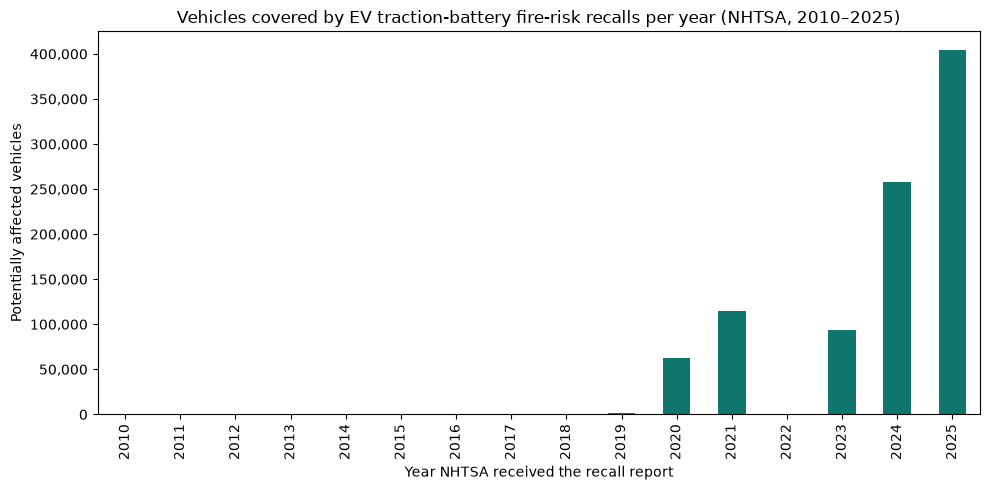

year
2010         0
2011       239
2012       108
2013         0
2014         0
2015         0
2016         0
2017         0
2018         0
2019      1646
2020     62862
2021    114524
2022       861
2023     94081
2024    258195
2025    404797
Name: POTAFF, dtype: int64


In [7]:
hv_vehicles = (hv[hv["year"] <= 2025].groupby("year")["POTAFF"].sum()
               .reindex(range(2010, 2026), fill_value=0))   # show every year, 0 where no recalls

ax = hv_vehicles.plot(kind="bar", color="#0F766E", figsize=(10, 5))
ax.set_title("Vehicles covered by EV traction-battery fire-risk recalls per year (NHTSA, 2010–2025)")
ax.set_xlabel("Year NHTSA received the recall report")
ax.set_ylabel("Potentially affected vehicles")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("../figures/03_hv_affected_vehicles.png", dpi=150)
plt.show()
print(hv_vehicles)

In [8]:
# Why is Tesla missing? Check its recalls in the full vehicle set
tesla = rec[rec["MFGNAME"].str.contains("TESLA", case=False)]
print("Tesla vehicle recalls (2010–2025):", len(tesla))
print("…with traction-battery component:", tesla["hv_comp"].sum())
print("…flagged battery + fire:", tesla["battery_fire"].sum())

Tesla vehicle recalls (2010–2025): 87
…with traction-battery component: 1
…flagged battery + fire: 1
